# 04 · Distribution parameters vs. threshold

If we fit a Gamma and a Weibull distribution to the waiting times above each threshold separately, how do the fitted shape and scale change with the threshold? 

We will assume a shape that stays roughly constant and a scale that grows with the threshold would support the model *scale(T) = b0 · T^b1* with a shared shape.

1. Use every observed peak-flux value between 5·10³ and 10⁵ SFU as a
   threshold (or, optionally, a log-spaced grid).
2. For each threshold, fit Gamma and Weibull by maximum likelihood and
   build 95% confidence intervals from the observed information (Hessian),
   see `srb.fitting.fit_with_confidence_intervals`.
3. Plot each parameter against the threshold together with three reference
   lines: constant, semi-log and log-log (power law).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from srb.config import FIGURES_DIR, TABLES_DIR
from srb.data import inter_event_times_by_threshold, load_catalogue
from srb.distributions import GAMMA, WEIBULL
from srb.fitting import fit_with_confidence_intervals
from srb.plotting import TREND_LABELS, plot_parameter_vs_threshold

## Parameters

In [2]:
START_THRESHOLD = 5000  # SFU
END_THRESHOLD = 100000  # SFU
NUM_THRESHOLDS = 20  # only used if USE_EVERY_OBSERVED_THRESHOLD is False
USE_EVERY_OBSERVED_THRESHOLD = True
CONFIDENCE_LEVEL = 0.95
MODELS = [GAMMA, WEIBULL]

## Thresholds

With `USE_EVERY_OBSERVED_THRESHOLD = True` every distinct peak flux in the
range is used, which gives the finest possible resolution: the set of
selected bursts only changes at those values.

In [3]:
df = load_catalogue()

if USE_EVERY_OBSERVED_THRESHOLD:
    thresholds = np.sort(df.loc[df["peak_flux"] >= START_THRESHOLD, "peak_flux"].unique())
else:
    thresholds = np.logspace(np.log10(START_THRESHOLD), np.log10(END_THRESHOLD), NUM_THRESHOLDS)
thresholds = thresholds[(thresholds >= START_THRESHOLD) & (thresholds <= END_THRESHOLD)]

groups = inter_event_times_by_threshold(df, thresholds)
print(f"{len(groups)} thresholds with enough data")

Skipping T = 88000.00: only 9 inter-event times
Skipping T = 98000.00: only 8 inter-event times
Skipping T = 99000.00: only 7 inter-event times
90 thresholds with enough data


## Fit every threshold

One row per threshold. Columns are prefixed with the model name, e.g.
`gamma_shape`, `gamma_shape_ci_lower`, `gamma_shape_ci_upper`,
`gamma_shape_se_log` (standard error on the log scale).

In [4]:
rows = []
for threshold, times in groups.items():
    row = {"threshold": threshold, "N": len(times)}
    for dist in MODELS:
        prefix = dist.name.lower()
        fit = fit_with_confidence_intervals(times, dist, level=CONFIDENCE_LEVEL)
        row.update({f"{prefix}_{key}": value for key, value in fit.items()})
    rows.append(row)

table = pd.DataFrame(rows)
table.to_csv(TABLES_DIR / "gamma_weibull_shape_scale_ci.csv", index=False)
table[["threshold", "N", "gamma_shape", "gamma_scale", "weibull_shape", "weibull_scale"]]

,threshold,N,gamma_shape,gamma_scale,weibull_shape,weibull_scale
0,5000.0,167,0.238150,539.689635,0.349616,36.444471
1,5100.0,164,0.237888,550.154794,0.349057,37.222570
2,5300.0,163,0.236727,556.248948,0.347406,37.070546
3,5400.0,162,0.236690,559.742604,0.347102,37.436633
4,5500.0,161,0.235532,566.046858,0.345435,37.270698
...,...,...,...,...,...,...
85,75000.0,15,0.448074,3073.727857,0.588604,1010.164112
86,77000.0,14,0.443878,3324.321206,0.585688,1096.395607
87,78000.0,12,0.402824,4273.557192,0.537972,1207.437019
88,81000.0,11,0.354093,5303.799776,0.485073,1095.199627


## Plots

For every model and parameter, one figure per reference line. The shaded
band is the confidence interval; the scale is in days.

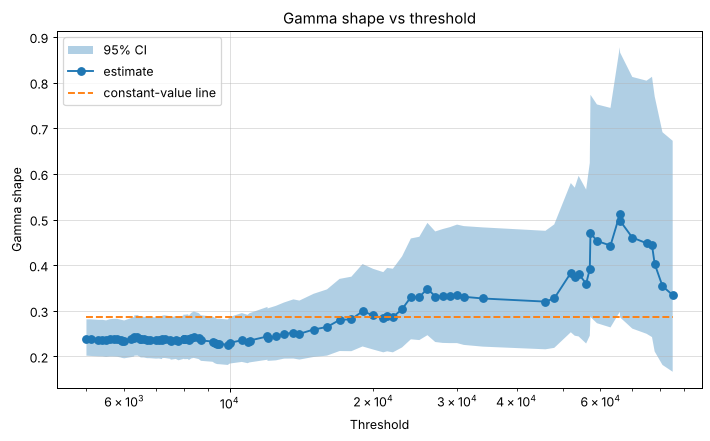

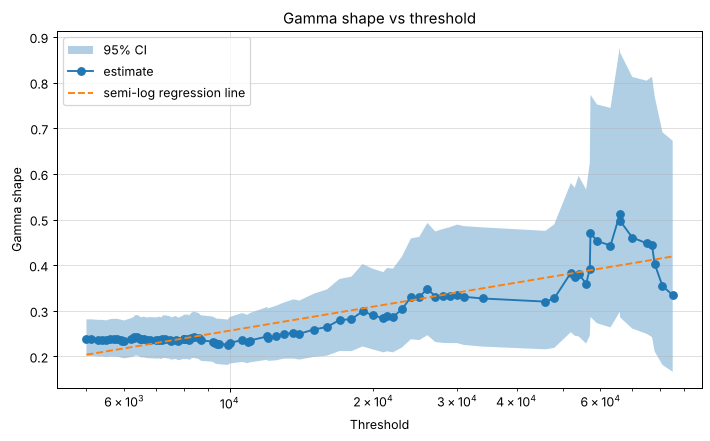

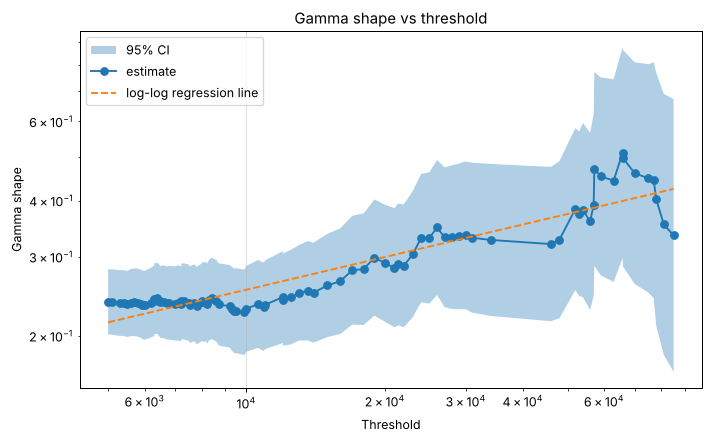

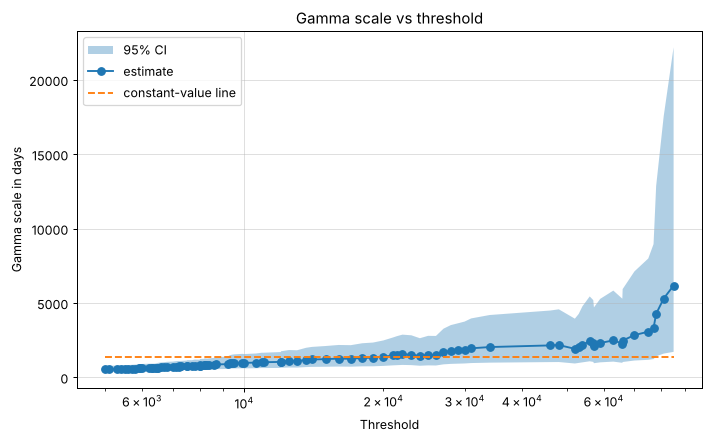

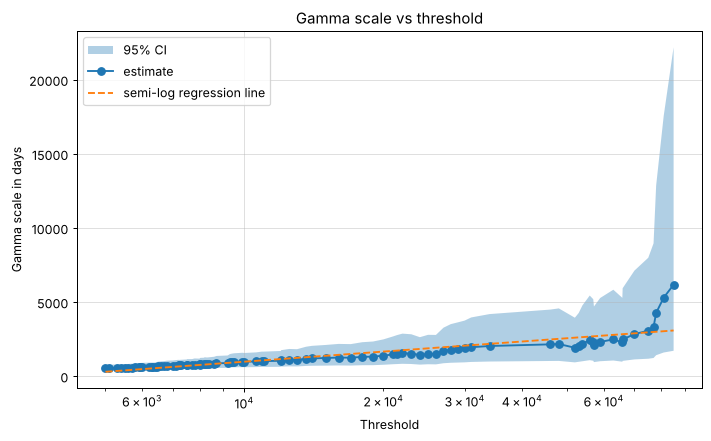

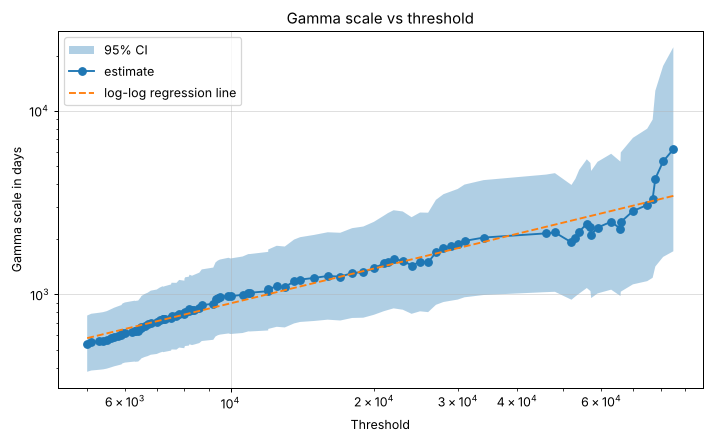

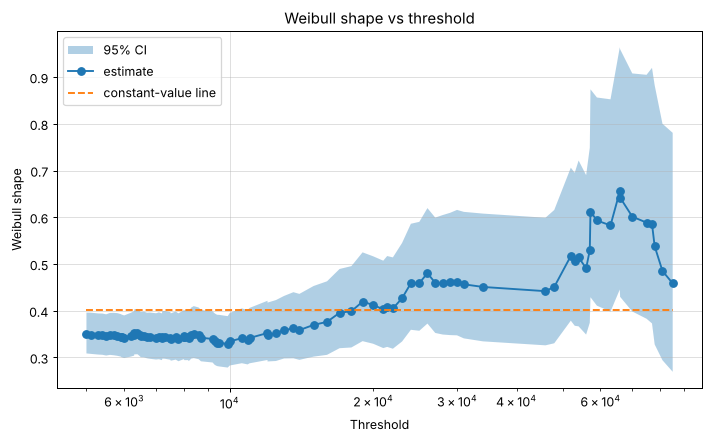

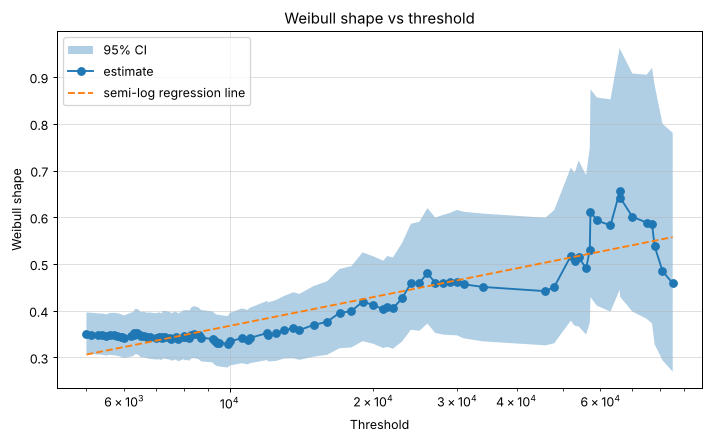

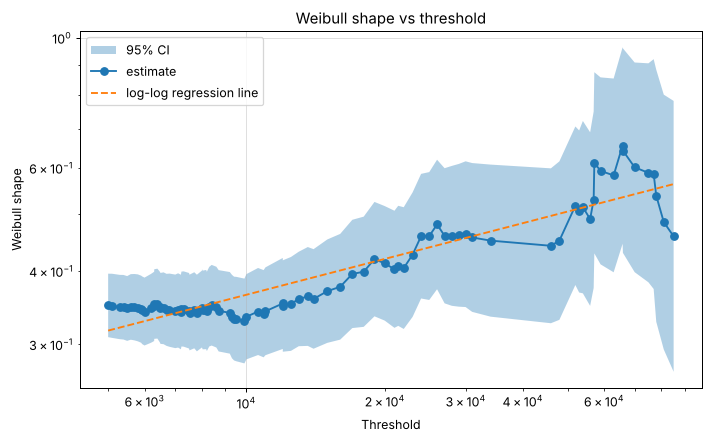

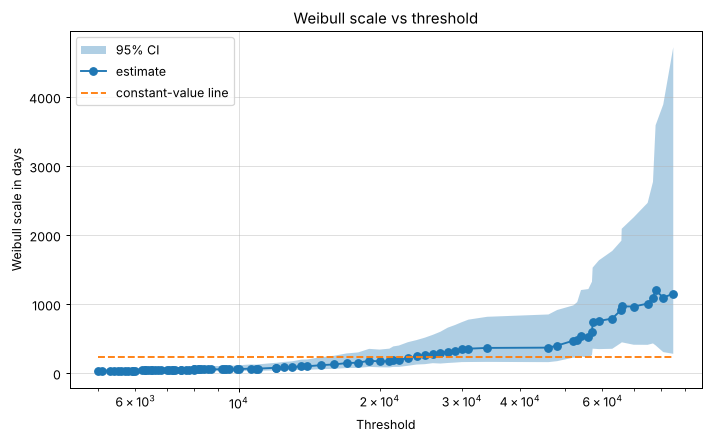

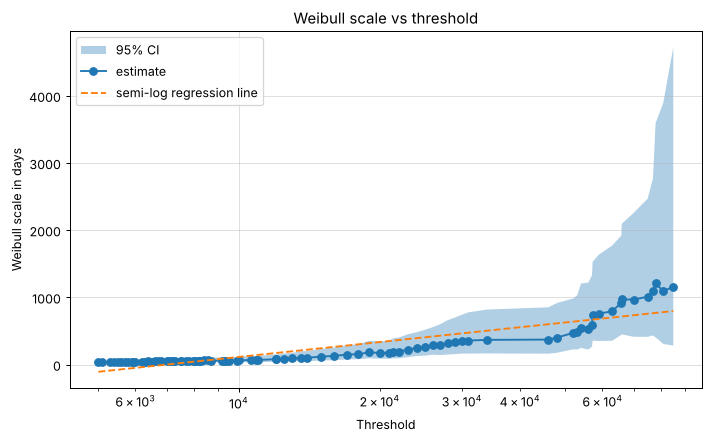

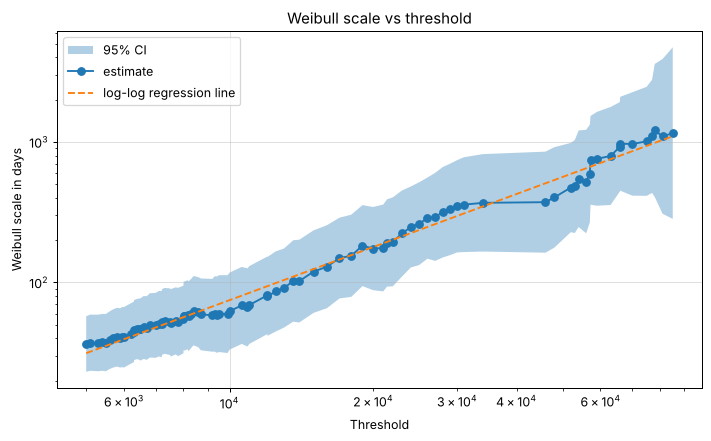

In [5]:
for dist in MODELS:
    prefix = dist.name.lower()
    for parameter, unit in [("shape", ""), ("scale", " in days")]:
        column = f"{prefix}_{parameter}"
        for kind in TREND_LABELS:
            fig = plot_parameter_vs_threshold(
                table,
                column,
                title=f"{dist.name} {parameter} vs threshold",
                y_label=f"{dist.name} {parameter}{unit}",
                kind=kind,
                level=CONFIDENCE_LEVEL,
            )
            fig.savefig(FIGURES_DIR / f"{column}_ci_{kind}.png", dpi=200)
            plt.show()